# 9장. Teacher 학습

In [1]:
# [준비 셀] 모든 노트북의 첫 코드 셀입니다. 항상 먼저 실행하세요.
from pathlib import Path
import sys

ROOT = Path.cwd().resolve().parents[1]          # docs/manual → 프로젝트 루트
assert (ROOT / "src/bearing_kd").exists(), "docs/manual 폴더에서 노트북을 열어야 합니다"
CODE = ROOT / "docs/manual/code"                 # 챕터별 완성 스크립트 위치
sys.path.insert(0, str(CODE))                    # 스크립트의 함수를 import 해서 쓰기 위해
print("프로젝트 루트 확인 완료:", ROOT.name)

프로젝트 루트 확인 완료: vib-onnx


이제 Teacher(MOMENT Base + LoRA + head)를 학습합니다. 2장에서 본 학습 루프 다섯 줄이 그대로 쓰입니다. 다른 점은 **입력이 청크**라는 것뿐입니다.

```text
DataLoader → 윈도우 [16,1,4000], 라벨 [16]
   → make_moment_chunks → 청크 [128,1,512], mask [128,512], 청크 라벨 [128]
   → Teacher → logits [128,2]
   → cross_entropy(logits, 청크 라벨)      ← Teacher는 청크 하나하나를 맞히도록 배운다
   → backward → validate_gradients → optimizer.step
```

| 설정 | 맛보기 (이 노트북) | 전체 (프로젝트) |
|---|---|---|
| 데이터 | 5장 split: train 84 / validation 28 윈도우 | v3 split: train 2,857 / validation 504 윈도우 |
| epoch | 3 | 20 (validation 100%에서 10에 중단) |
| learning rate | 1e-3 | 1e-4 |
| 시간 (Mac MPS) | 약 1분 | epoch당 약 10.7분 |

맛보기는 epoch당 step이 6번뿐이라 learning rate를 크게 했습니다. 전체 데이터는 epoch당 179 step이라 작은 값으로도 충분히 배웁니다.

In [2]:
import os, warnings
os.environ["HF_HUB_OFFLINE"] = "1"                 # 인터넷 없이 로컬 모델 폴더만 사용
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"    # Mac: MPS가 모르는 연산은 CPU로
warnings.filterwarnings("ignore")
import torch
from ch09_train_teacher import pick_device
DEVICE = pick_device()
print("장치:", DEVICE)

장치: mps


## 9.1 준비: 데이터, 모델, optimizer

In [3]:
import json
import torch.nn.functional as F
from torch.utils.data import DataLoader
import ch07_moment as ch07, ch08_lora as ch08
from ch06_dataset import WindowDataset, make_moment_chunks
from ch09_train_teacher import seed_everything

seed_everything(42)
split = json.loads((ROOT / "outputs/manual/split_holdout.json").read_text())
train_ds = WindowDataset([ROOT / f for f in split["train"]])
loader = DataLoader(train_ds, batch_size=16, shuffle=True, generator=torch.Generator().manual_seed(42))

model = ch08.add_lora(ch07.load_moment(ROOT / "models/MOMENT-1-base")).to(DEVICE)
params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.AdamW(params, lr=1e-3)
print(f"학습 대상 {sum(p.numel() for p in params):,}개를 AdamW로 학습")

Loading weights from local directory
학습 대상 296,450개를 AdamW로 학습


**AdamW**: 2장의 SGD보다 똑똑한 optimizer입니다. 파라미터마다 최근 기울기의 크기를 기억해 보폭을 자동으로 조절합니다. 대부분의 딥러닝에서 기본으로 씁니다. 그래서 optimizer도 상태를 갖고, 체크포인트에 함께 저장합니다(10장).

## 9.2 학습 step 한 번을 한 줄씩

In [4]:
model.train()                                          # 학습 모드: dropout 켜짐
x, y = next(iter(loader))
x, y = x.to(DEVICE), y.to(DEVICE)
chunks, mask, chunk_y = make_moment_chunks(x, y)
print("① 입력", tuple(x.shape), "→ 청크", tuple(chunks.shape))

logits = model(x_enc=chunks, input_mask=mask).logits
print("② logits", tuple(logits.shape))

loss = F.cross_entropy(logits, chunk_y)
print("③ loss", round(loss.item(), 4), "(찍는 수준이면 약 0.693)")

optimizer.zero_grad(set_to_none=True)
loss.backward()
ch08.validate_gradients(model)
print("④ backward 완료, 모든 LoRA와 head에 기울기 있음")

b_before = model.encoder.block[0].layer[0].SelfAttention.q.lora_B.default.weight.abs().sum().item()
optimizer.step()
b_after = model.encoder.block[0].layer[0].SelfAttention.q.lora_B.default.weight.abs().sum().item()
print(f"⑤ step: 첫 LoRA B의 크기 {b_before:.4f} → {b_after:.4f}  (0에서 움직이기 시작)")

① 입력 (16, 1, 4000) → 청크 (128, 1, 512)
② logits (128, 2)


③ loss 0.7115 (찍는 수준이면 약 0.693)


④ backward 완료, 모든 LoRA와 head에 기울기 있음
⑤ step: 첫 LoRA B의 크기 0.0000 → 6.0992  (0에서 움직이기 시작)


## 9.3 validation: 윈도우 단위로 평가

학습은 청크 단위지만 **판정은 윈도우 단위**입니다. 윈도우 하나의 청크 8개 logits를 **평균**한 뒤 argmax 합니다.

```python
def window_logits(model, batch_x):
    chunks, mask, _ = make_moment_chunks(batch_x)
    logits = model(x_enc=chunks, input_mask=mask).logits     # [B*8, 2]
    return logits.reshape(batch_x.shape[0], -1, 2).mean(dim=1)   # [B, 8, 2] → 평균 → [B, 2]
```

## 9.4 최고 모델 고르기: 이 프로젝트가 배운 것

매 epoch 끝에 validation 성능이 가장 좋으면 저장합니다. 그런데 비교 규칙에 함정이 있었습니다.

| 규칙 | 문제 |
|---|---|
| 정확도가 **같거나 높으면** 저장 (프로젝트 코드) | 100%가 계속 나오면 계속 덮어써서, 원하던 epoch 4가 사라졌다 |
| 정확도가 **더 높을 때만** 저장 | 첫 epoch부터 100%면 덜 학습된 epoch 1이 끝까지 남는다 |
| **(정확도, -loss) 순으로 비교** (매뉴얼 코드) | 정확도가 같으면 더 확신하는(loss가 낮은) epoch를 고른다 |

그리고 **epoch마다 학습된 부분(LoRA + head, 약 1.2 MB)만** 따로 저장해서, 나중에 어떤 epoch로든 되돌릴 수 있게 합니다(10장).

## 9.5 맛보기 학습 실행 (약 1분)

In [5]:
del model, optimizer
import gc; gc.collect()

120

In [6]:
%run code/ch09_train_teacher.py

장치 mps | train 84 윈도우, validation 28 윈도우


Loading weights from local directory
학습 대상 파라미터 296,450개


epoch  1  train loss 0.6770  validation 28/28 loss 0.5684 [[14, 0], [0, 14]]  17.6s  ← best 저장


epoch  2  train loss 0.4903  validation 28/28 loss 0.2651 [[14, 0], [0, 14]]  17.6s  ← best 저장


epoch  3  train loss 0.1711  validation 28/28 loss 0.0176 [[14, 0], [0, 14]]  17.7s  ← best 저장


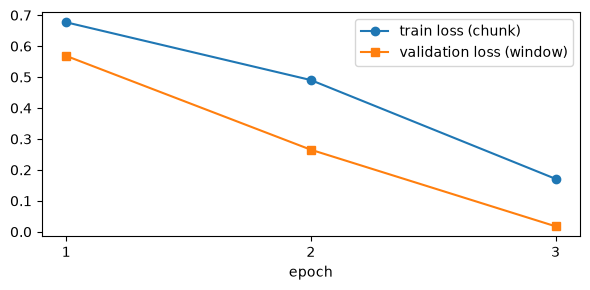

validation 정확도: [1.0, 1.0, 1.0]


In [7]:
import matplotlib.pyplot as plt
history = json.loads((ROOT / "outputs/manual/teacher/history.json").read_text())
ep = [h["epoch"] for h in history]
plt.figure(figsize=(6, 3))
plt.plot(ep, [h["train_loss"] for h in history], "o-", label="train loss (chunk)")
plt.plot(ep, [h["validation"]["loss"] for h in history], "s-", label="validation loss (window)")
plt.xlabel("epoch"); plt.xticks(ep); plt.legend(); plt.tight_layout(); plt.show()
print("validation 정확도:", [h["validation"]["accuracy"] for h in history])

validation이 첫 epoch부터 100%입니다. 좋아 보이지만, 5장에서 봤듯이 이 validation은 **train과 같은 베어링(K001, KA03)의 다른 파일**입니다. 처음 보는 베어링에서도 잘하는지는 12장에서 확인합니다.

## 9.6 전체 학습 (터미널에서)

노트북은 창을 닫으면 학습이 멈추므로, 오래 걸리는 학습은 터미널에서 돌리세요.

```bash
source .venv-uv/bin/activate
PYTORCH_ENABLE_MPS_FALLBACK=1 python docs/manual/code/ch09_train_teacher.py \
    --split data/splits/bearing_holdout_v3.json --epochs 20 --learning-rate 1e-4 \
    --output-dir outputs/manual/teacher_full
```

- Mac이 잠들면 학습도 멈춥니다. 전원을 연결하고 `caffeinate -i -s`로 잠자기를 막으세요.
- 실제 프로젝트 명령: `bearing-kd train-teacher --split ... --output-dir ... --device mps`

## 9장 완성 코드: `code/ch09_train_teacher.py`

In [8]:
from IPython.display import Code
Code(filename=str(CODE / "ch09_train_teacher.py"), language="python")

"""9장 완성 코드: Teacher(MOMENT Base + LoRA + head)를 학습한다.

src/bearing_kd/training.py의 train(teacher=True)을 읽기 쉽게 줄인 버전이다.
프로젝트 코드와 다른 점 (프로젝트에서 겪은 문제를 반영한 개선):
    - 최고 모델은 (validation 정확도, -validation loss) 순으로 비교한다.
      정확도가 100%에 붙어 같아져도 loss가 더 낮은(더 확신하는) epoch를 고른다.
    - epoch마다 학습된 부분(LoRA + head)만 작게 따로 저장한다 → 원하는 epoch로 되돌릴 수 있다.

실행 (프로젝트 루트에서):
    # 맛보기: 4·5장 결과(작은 split), 3 epoch, learning rate 1e-3 (약 1분)
    python docs/manual/code/ch09_train_teacher.py
    # 전체: 실제 프로젝트 split, 프로젝트와 같은 설정 (Mac MPS 기준 약 3.5시간)
    PYTORCH_ENABLE_MPS_FALLBACK=1 python docs/manual/code/ch09_train_teacher.py \
        --split data/splits/bearing_holdout_v3.json --epochs 20 --learning-rate 1e-4 --output-dir outputs/manual/teacher_full
"""

import argparse
import json
import random
import time
import warnings
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader

from ch06_dataset import WindowDataset, make_moment_chunks
from ch07_moment import ROOT, load_moment
from ch08_lora import LORA_CONFIG, add_lora, validate_gradients


def seed_everything(seed):
    """무작위성이 들어가는 모든 곳의 시작점을 고정한다."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def pick_device(name="auto"):
    if name != "auto":
        return name
    return "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"


def window_logits(model, batch_x):
    """윈도우 [B,1,4000] → 청크 8개씩 예측 → 8개 logits 평균 → [B,2]."""
    chunks, mask, _ = make_moment_chunks(batch_x)
    logits = model(x_enc=chunks, input_mask=mask).logits
    return logits.reshape(batch_x.shape[0], -1, 2).mean(dim=1)


@torch.no_grad()
def evaluate(model, dataset, device, batch_size=32):
    model.eval()
    all_logits = []
    for x, _ in DataLoader(dataset, batch_size=batch_size):
        all_logits.append(window_logits(model, x.to(device)).cpu())
    logits = torch.cat(all_logits)
    labels = dataset.labels
    loss = F.cross_entropy(logits, torch.from_numpy(labels)).item()   # 윈도우 단위 validation loss
    pred = logits.argmax(1).numpy()
    confusion = np.zeros((2, 2), dtype=int)
    np.add.at(confusion, (labels, pred), 1)
    return {"accuracy": float((pred == labels).mean()), "correct": int((pred == labels).sum()),
            "total": len(labels), "loss": loss, "confusion_matrix": confusion.tolist()}


def trainable_state(model):
    """학습된 부분(LoRA + head)만 뽑는다. 전체 457 MB 대신 약 1 MB."""
    return {k: v.detach().cpu().clone() for k, v in model.state_dict().items() if "lora_" in k or k.startswith("head.")}


def train_teacher(split_path, model_dir, output_dir, epochs=3, batch_size=16, lr=1e-3, seed=42, device="auto"):
    device = pick_device(device)
    seed_everything(seed)
    split = json.loads(Path(split_path).read_text())
    train_ds = WindowDataset([ROOT / f for f in split["train"]])
    valid_ds = WindowDataset([ROOT / f for f in split["validation"]])
    print(f"장치 {device} | train {len(train_ds)} 윈도우, validation {len(valid_ds)} 윈도우")

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        model = add_lora(load_moment(model_dir, seed=seed)).to(device)
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(params, lr=lr)
    print(f"학습 대상 파라미터 {sum(p.numel() for p in params):,}개")

    output_dir = Path(output_dir)
    (output_dir / "epochs").mkdir(parents=True, exist_ok=True)
    config = {"model_dir": str(Path(model_dir).relative_to(ROOT)), "split": str(Path(split_path).relative_to(ROOT)),
              "epochs": epochs, "batch_size": batch_size, "learning_rate": lr, "seed": seed, "device": device,
              "lora_config": LORA_CONFIG, "train_fingerprint": train_ds.fingerprint}
    (output_dir / "training_config.json").write_text(json.dumps(config, indent=2) + "\n")

    loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, generator=torch.Generator().manual_seed(seed))